In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:

from pathlib import Path

# Ganti dengan lokasi folder dataset kamu
DATASET_DIR = Path(r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee")

# Ekstensi gambar yang akan diperiksa
ekstensi_gambar = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

if not DATASET_DIR.exists():
    print("Folder dataset tidak ditemukan!")
    print("Periksa kembali lokasi folder.")
else:
    print("Dataset ditemukan:", DATASET_DIR)
    print()

    total_gambar = 0

    for folder in sorted(DATASET_DIR.iterdir()):
        if folder.is_dir():
            gambar = [
                file for file in folder.rglob("*")
                if file.is_file()
                and file.suffix.lower() in ekstensi_gambar
            ]

            print(f"{folder.name}: {len(gambar)} gambar")
            total_gambar += len(gambar)

    print("-" * 35)
    print("Total gambar:", total_gambar)


Dataset ditemukan: D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee

Daunsehat: 400 gambar
Leafcurl: 400 gambar
yelowwiss: 400 gambar
-----------------------------------
Total gambar: 1200


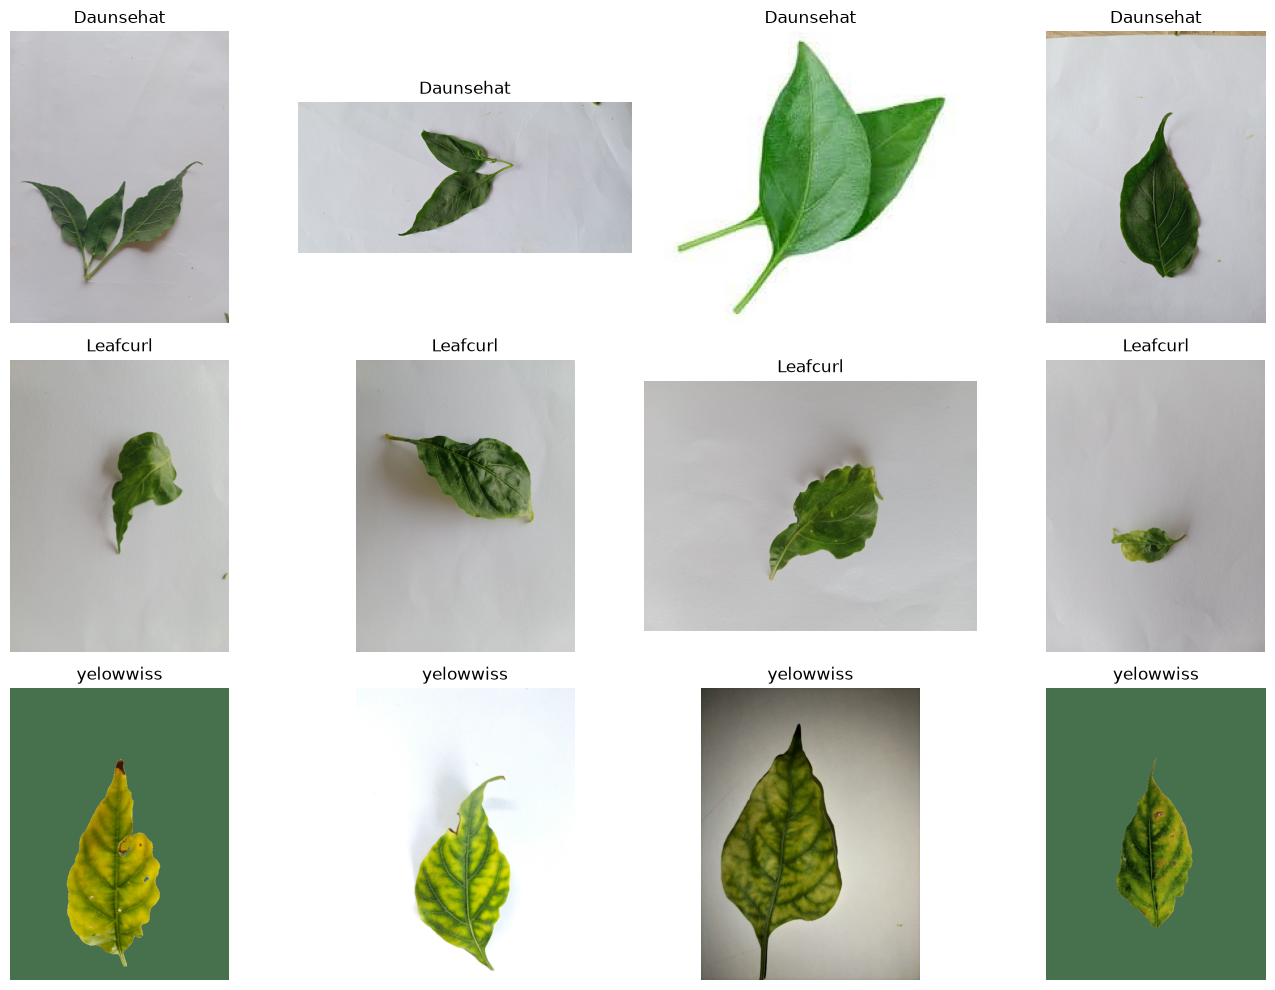

In [8]:
import random
from PIL import Image
DATASET_DIR = Path(
    r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee"
)

random.seed(42)


kelas = ["Daunsehat","Leafcurl","yelowwiss"]
ekstensi = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for i, nama_kelas in enumerate(kelas):
    folder = DATASET_DIR / nama_kelas

    gambar = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in ekstensi
    ]

    sampel = random.sample(gambar, min(4, len(gambar)))

    for j, path in enumerate(sampel):
        with Image.open(path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(nama_kelas)
        axes[i, j].axis("off")

    for j in range(len(sampel), 4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [11]:
from collections import Counter

DATASET_DIR = Path(
    r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee"
)

ekstensi = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in sorted(DATASET_DIR.iterdir()):
    if not folder.is_dir():
        continue

    ukuran = Counter()
    mode_warna = Counter()
    gambar_rusak = []

    for path in folder.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in ekstensi:
            continue

        try:
            with Image.open(path) as img:
                ukuran[img.size] += 1
                mode_warna[img.mode] += 1
                img.verify()
        except Exception:
            gambar_rusak.append(path.name)

    print(f"\nKelas: {folder.name}")
    print("Jumlah ukuran berbeda:", len(ukuran))
    print("Ukuran terbanyak:", ukuran.most_common(5))
    print("Mode warna:", mode_warna)
    print("Jumlah gambar bermasalah:", len(gambar_rusak))



Kelas: Daunsehat
Jumlah ukuran berbeda: 26
Ukuran terbanyak: [((3072, 4080), 105), ((4080, 3072), 75), ((4080, 3060), 50), ((3060, 4080), 45), ((225, 225), 35)]
Mode warna: Counter({'RGB': 400})
Jumlah gambar bermasalah: 0

Kelas: Leafcurl
Jumlah ukuran berbeda: 6
Ukuran terbanyak: [((3060, 4080), 196), ((3072, 4080), 161), ((4080, 3060), 37), ((4080, 3072), 4), ((3060, 2843), 1)]
Mode warna: Counter({'RGB': 400})
Jumlah gambar bermasalah: 0

Kelas: yelowwiss
Jumlah ukuran berbeda: 11
Ukuran terbanyak: [((3000, 4000), 265), ((433, 577), 58), ((4000, 3000), 33), ((3072, 4080), 21), ((433, 576), 10)]
Mode warna: Counter({'RGB': 326, 'P': 74})
Jumlah gambar bermasalah: 0


In [12]:
from collections import defaultdict
import hashlib

ekstensi = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
hash_files = defaultdict(list)

for folder in DATASET_DIR.iterdir():
    if not folder.is_dir():
        continue

    for path in folder.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in ekstensi:
            continue

        with open(path, "rb") as f:
            digest = hashlib.sha256(f.read()).hexdigest()

        hash_files[digest].append((folder.name, path.name))

duplikat = {
    digest: files
    for digest, files in hash_files.items()
    if len(files) > 1
}

print("File file identik/duplikat :", len(duplikat))

for i, files in enumerate(duplikat.values(), start=1):
    print(f"\nKelompok {i}:")
    for kelas, nama_file in files:
        print(f"  {kelas}/{nama_file}")


File file identik/duplikat : 120

Kelompok 1:
  Daunsehat/1.jpeg
  Daunsehat/7.jpeg

Kelompok 2:
  Daunsehat/101.jpg
  Daunsehat/126.jpg
  Daunsehat/127.jpg
  Daunsehat/128.jpg
  Daunsehat/129.jpg
  Daunsehat/130.jpg
  Daunsehat/131.jpg
  Daunsehat/132.jpg
  Daunsehat/133.jpg

Kelompok 3:
  Daunsehat/102.jpg
  Daunsehat/103.jpg
  Daunsehat/104.jpg
  Daunsehat/32.jpg

Kelompok 4:
  Daunsehat/108.jpg
  Daunsehat/16.jpeg

Kelompok 5:
  Daunsehat/11.jpeg
  Daunsehat/3.jpeg
  Daunsehat/4.jpeg

Kelompok 6:
  Daunsehat/112.jpg
  Daunsehat/113.jpg
  Daunsehat/114.jpg
  Daunsehat/115.jpg
  Daunsehat/116.jpg
  Daunsehat/117.jpg
  Daunsehat/118.jpg
  Daunsehat/29.jpg

Kelompok 7:
  Daunsehat/119.jpg
  Daunsehat/120.jpg
  Daunsehat/121.jpg
  Daunsehat/122.jpg
  Daunsehat/123.jpg
  Daunsehat/124.jpg
  Daunsehat/125.jpg
  Daunsehat/38.jpg

Kelompok 8:
  Daunsehat/134.jpg
  Daunsehat/135.jpg
  Daunsehat/136.jpg
  Daunsehat/137.jpg
  Daunsehat/138.jpg
  Daunsehat/139.jpg
  Daunsehat/140.jpg
  Daunseha

In [13]:
from collections import defaultdict
import hashlib

ekstensi = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
hash_files = defaultdict(list)

for folder in DATASET_DIR.iterdir():
    if not folder.is_dir():
        continue

    for path in folder.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in ekstensi:
            continue

        with open(path, "rb") as f:
            digest = hashlib.sha256(f.read()).hexdigest()

        # Simpan objek path lengkapnya
        hash_files[digest].append(path)

duplikat = {
    digest: paths
    for digest, paths in hash_files.items()
    if len(paths) > 1
}

print(f"Total kelompok duplikat: {len(duplikat)}")

Total kelompok duplikat: 120


In [14]:
import hashlib
from pathlib import Path
import shutil

# Tentukan lokasi folder tujuan yang baru (akan dibuat otomatis)
CLEAN_DATASET_DIR = DATASET_DIR.parent / f"{DATASET_DIR.name}_clean"

ekstensi = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
seen_hashes = set()
total_disalin = 0
total_dilewati = 0

for folder in DATASET_DIR.iterdir():
    if not folder.is_dir():
        continue

    for path in folder.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in ekstensi:
            continue

        # Hitung hash file
        with open(path, "rb") as f:
            digest = hashlib.sha256(f.read()).hexdigest()

        # Jika hash sudah pernah ditemukan sebelumnya, lewati (jangan disalin)
        if digest in seen_hashes:
            total_dilewati += 1
            continue

        seen_hashes.add(digest)

        # Buat struktur subfolder yang sama di dalam folder tujuan baru
        relative_path = path.relative_to(DATASET_DIR)
        dest_path = CLEAN_DATASET_DIR / relative_path
        dest_path.parent.mkdir(parents=True, exist_ok=True)

        # Salin file beserta metadatanya ke folder baru
        shutil.copy2(path, dest_path)
        total_disalin += 1

print(f"Selesai! Dataset bersih disimpan di: {CLEAN_DATASET_DIR}")
print(f"Total foto unik disalin   : {total_disalin} file")
print(f"Total foto duplikat dilewati: {total_dilewati} file")

Selesai! Dataset bersih disimpan di: D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_clean
Total foto unik disalin   : 529 file
Total foto duplikat dilewati: 671 file


In [15]:
DATASET_DIR = Path(r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_clean")

# Ekstensi gambar yang akan diperiksa
ekstensi_gambar = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

if not DATASET_DIR.exists():
    print("Folder dataset tidak ditemukan!")
    print("Periksa kembali lokasi folder.")
else:
    print("Dataset ditemukan:", DATASET_DIR)
    print()

    total_gambar = 0

    for folder in sorted(DATASET_DIR.iterdir()):
        if folder.is_dir():
            gambar = [
                file for file in folder.rglob("*")
                if file.is_file()
                and file.suffix.lower() in ekstensi_gambar
            ]

            print(f"{folder.name}: {len(gambar)} gambar")
            total_gambar += len(gambar)

    print("-" * 35)
    print("Total gambar:", total_gambar)

Dataset ditemukan: D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_clean

Daunsehat: 135 gambar
Leafcurl: 53 gambar
yelowwiss: 341 gambar
-----------------------------------
Total gambar: 529


In [16]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageOps

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
from skimage.feature import graycomatrix, graycoprops

# 1. Load path dan label dari dataset bersih
DATASET_DIR = Path(r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_clean")
ekstensi_gambar = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths = []
labels = []

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in ekstensi_gambar:
                paths.append(file)
                labels.append(folder.name)

# 2. Split 80% Train, 20% Test dengan stratify agar proporsi kelas seimbang
X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    paths, labels, test_size=0.20, random_state=42, stratify=labels
)

print(f"Total Data Latih (Asli): {len(X_train_paths)} gambar")
print(f"Total Data Uji (Murni) : {len(X_test_paths)} gambar")

Total Data Latih (Asli): 423 gambar
Total Data Uji (Murni) : 106 gambar


In [17]:
from pathlib import Path
import random
import shutil
from PIL import Image, ImageEnhance, ImageOps
from sklearn.model_selection import train_test_split

# 1. Konfigurasi Direktori
SOURCE_DIR = Path(r"D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_clean")
BASE_OUTPUT_DIR = SOURCE_DIR.parent / "dauncabee_split_aug"

TRAIN_ASLI_DIR = BASE_OUTPUT_DIR / "train_asli"      # Untuk Skenario 1 (Tanpa Augmentasi)
TRAIN_AUG_DIR  = BASE_OUTPUT_DIR / "train_aug"       # Untuk Skenario 2 (Dengan Augmentasi)
TEST_DIR       = BASE_OUTPUT_DIR / "test_murni"      # Data Uji yang sama untuk kedua skenario

ekstensi_gambar = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(42)

# 2. Fungsi Augmentasi Gambar Daun
def augmentasi_gambar(img):
    if img.mode != "RGB":
        img = img.convert("RGB")
        
    if random.random() > 0.5:
        img = ImageOps.mirror(img)
    if random.random() > 0.5:
        img = ImageOps.flip(img)
        
    sudut = random.uniform(-35, 35)
    img = img.rotate(sudut, resample=Image.BICUBIC, expand=False)
    img = ImageEnhance.Brightness(img).enhance(random.uniform(0.85, 1.15))
    img = ImageEnhance.Contrast(img).enhance(random.uniform(0.85, 1.15))
    
    w, h = img.size
    zoom = random.uniform(0.85, 0.95)
    new_w, new_h = int(w * zoom), int(h * zoom)
    left = random.randint(0, w - new_w)
    top = random.randint(0, h - new_h)
    img = img.crop((left, top, left + new_w, top + new_h)).resize((w, h), resample=Image.BICUBIC)
    return img

# 3. Kumpulkan semua path dan label dari dataset bersih
paths, labels = [], []
for folder in sorted(SOURCE_DIR.iterdir()):
    if folder.is_dir():
        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in ekstensi_gambar:
                paths.append(file)
                labels.append(folder.name)

# 4. Bagi menjadi 80% Train dan 20% Test (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    paths, labels, test_size=0.20, random_state=42, stratify=labels
)

# 5. Salin Data Uji ke folder 'test_murni'
for path, label in zip(X_test, y_test):
    dest = TEST_DIR / label
    dest.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, dest / path.name)

# 6. Salin Data Latih ke 'train_asli' dan 'train_aug'
train_per_kelas = {}
for path, label in zip(X_train, y_train):
    train_per_kelas.setdefault(label, []).append(path)
    
    # Salin ke folder train_asli (Skenario 1)
    dest_asli = TRAIN_ASLI_DIR / label
    dest_asli.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, dest_asli / path.name)
    
    # Salin gambar asli ke folder train_aug (Skenario 2)
    dest_aug = TRAIN_AUG_DIR / label
    dest_aug.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, dest_aug / path.name)

# 7. Lakukan Augmentasi HANYA di dalam folder 'train_aug' agar seimbang
target_jumlah = max(len(v) for v in train_per_kelas.values())
print(f"Target jumlah gambar per kelas di 'train_aug': {target_jumlah} gambar\n")

for label, class_paths in train_per_kelas.items():
    dest_aug = TRAIN_AUG_DIR / label
    jumlah_asli = len(class_paths)
    kekurangan = target_jumlah - jumlah_asli
    
    print(f"Kelas '{label}': {jumlah_asli} asli + {kekurangan} augmentasi -> Total {target_jumlah}")
    
    for i in range(1, kekurangan + 1):
        sumber_path = random.choice(class_paths)
        with Image.open(sumber_path) as img:
            img_aug = augmentasi_gambar(img)
            nama_baru = f"aug_{i:03d}_{sumber_path.stem}.jpg"
            img_aug.save(dest_aug / nama_baru, quality=95)

print("\n" + "=" * 50)
print(f"Selesai! Folder dataset siap digunakan di:\n{BASE_OUTPUT_DIR}")

Target jumlah gambar per kelas di 'train_aug': 273 gambar

Kelas 'yelowwiss': 273 asli + 0 augmentasi -> Total 273
Kelas 'Daunsehat': 108 asli + 165 augmentasi -> Total 273
Kelas 'Leafcurl': 42 asli + 231 augmentasi -> Total 273

Selesai! Folder dataset siap digunakan di:
D:\File Tugas Kuliah\File_Semester5\Dataset\dauncabee_split_aug
